# Elia solar data (ods032): quality checks and first look

This notebook checks the Elia file on its own, before it is joined to weather.

**File:** `ods032.parquet`, built by `download_elia.py` from Elia Open Data. One row per area per 15 minutes:
measured solar output, Elia's forecasts with P10 and P90 bands, and monitored capacity, for 10 provinces, Brussels,
Flanders, Wallonia and Belgium.

**Sections**
1. Load
2. Quality checks (seven of them)
3. Figures: generation through the year, load factor by day and hour, sample weeks
4. How good are Elia's own forecasts? This is the benchmark the project has to face.

**The analysis is on one area, set by `PROVINCE` (Antwerp).** The file holds all areas, and two checks use them:
whether the provinces add up to the totals (2.3), and how Elia's forecast error in the chosen area compares with the others (4.1).

`START` sets where the checks begin (the modelling sample starts in January 2021). `FIG_YEAR` picks the year shown
in the three descriptive figures. Needs `pandas`, `pyarrow`, `matplotlib`, `numpy`.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ELIA_FILE = Path("ods032.parquet")
PROVINCE = "Antwerp"      # the area the analysis is run on
START = "2021-01-01"      # first day used in the checks and the forecast-accuracy figures
FIG_YEAR = 2025           # year shown in the daily generation, heatmap and sample-week figures
SAVE_FIGURES = False      # set True to also write each figure to the figures/ folder

# chart style
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
BLUE_LIGHT = "#b7d3f6"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.edgecolor": AXIS, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False,
})

FORECASTS = {            # column prefix -> label shown on charts
    "mostrecent": "Most recent (intraday)",
    "dayahead11h": "Day-ahead, 11:00",
    "dayahead": "Day-ahead, latest",
    "weekahead": "Week-ahead",
}
REGION_GROUPS = {        # aggregate -> the areas that should add up to it
    "Flanders": ["Antwerp", "East-Flanders", "Flemish-Brabant", "Limburg", "West-Flanders"],
    "Wallonia": ["Hainaut", "Liège", "Luxembourg", "Namur", "Walloon-Brabant"],
    "Belgium": ["Flanders", "Wallonia", "Brussels"],
}
AGGREGATES = list(REGION_GROUPS)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Load

Timestamps are converted to Belgian local time for the charts. The load factor is recomputed here as measured
output divided by monitored capacity, so it can be compared with the one Elia publishes.

In [2]:
def load(path):
    df = pd.read_parquet(path)
    df["datetime"] = pd.to_datetime(df["datetime"], utc=True).dt.tz_convert("Europe/Brussels")
    df = df.sort_values(["region", "datetime"]).reset_index(drop=True)
    # load factor as a 0-1 fraction of monitored capacity, recomputed by us
    df["lf"] = df["measured"] / df["monitoredcapacity"]
    return df

def section(title):
    print(f"\n{'=' * 70}\n{title}\n{'=' * 70}")


full = load(ELIA_FILE)
areas = full[full["datetime"] >= pd.Timestamp(START, tz="Europe/Brussels")].reset_index(drop=True)   # every area
df = areas[areas["region"] == PROVINCE].reset_index(drop=True)                                       # the working area
fig_df = df[df["datetime"].dt.year == FIG_YEAR]

print(f"Whole file: {len(full):,} rows, {full['region'].nunique()} areas, {full['datetime'].min():%d %b %Y} to {full['datetime'].max():%d %b %Y}")
print(f"{PROVINCE} from {START}: {len(df):,} rows   |   Figures for {FIG_YEAR}: {len(fig_df):,} rows")
df.head()

Whole file: 2,978,360 rows, 14 areas, 01 Oct 2020 to 25 Oct 2026
Antwerp from 2021-01-01: 203,904 rows   |   Figures for 2025: 35,040 rows


,datetime,resolutioncode,region,measured,mostrecentforecast,mostrecentconfidence10,mostrecentconfidence90,dayahead11hforecast,dayahead11hconfidence10,dayahead11hconfidence90,dayaheadforecast,dayaheadconfidence10,dayaheadconfidence90,weekaheadforecast,weekaheadconfidence10,weekaheadconfidence90,monitoredcapacity,loadfactor,lf
0,2021-01-01 00:00:00+01:00,PT15M,Antwerp,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,776.79,0.00,0.00
1,2021-01-01 00:15:00+01:00,PT15M,Antwerp,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,776.79,0.00,0.00
2,2021-01-01 00:30:00+01:00,PT15M,Antwerp,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,776.79,0.00,0.00
3,2021-01-01 00:45:00+01:00,PT15M,Antwerp,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,776.79,0.00,0.00
4,2021-01-01 01:00:00+01:00,PT15M,Antwerp,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,776.79,0.00,0.00


## 2. Quality checks

In [3]:
def forecast_scores(df, region):
    g = df[(df["region"] == region)].dropna(subset=["measured"])
    g = g[(g["measured"] > 0) | (g["dayaheadforecast"] > 0)]
    cap = g["monitoredcapacity"]
    rows = {}
    for pre, label in FORECASTS.items():
        err = g[f"{pre}forecast"] - g["measured"]
        rows[label] = {
            "nMAE %": (err.abs() / cap).mean() * 100,
            "nRMSE %": np.sqrt(((err / cap) ** 2).mean()) * 100,
            "bias %": (err / cap).mean() * 100,
            "below P10 %": (g["measured"] < g[f"{pre}confidence10"]).mean() * 100,
            "inside %": ((g["measured"] >= g[f"{pre}confidence10"])
                         & (g["measured"] <= g[f"{pre}confidence90"])).mean() * 100,
            "above P90 %": (g["measured"] > g[f"{pre}confidence90"]).mean() * 100,
        }
    return pd.DataFrame(rows).T

### 2.1 Shape and coverage
The area should have one row for every 15 minute step, with no repeats.

In [4]:
start, end = df["datetime"].min(), df["datetime"].max()
print(f"Rows: {len(df):,}   Columns: {df.shape[1] - 1}   Regions: {df['region'].nunique()}")
print(f"From {start}  to  {end}")
expected = int((end - start) / pd.Timedelta("15min")) + 1
per_region = df.groupby("region").size()
print(f"Expected 15-min steps per region: {expected:,}")
print(f"Actual steps per region: min {per_region.min():,}, max {per_region.max():,}")
dups = df.duplicated(["region", "datetime"]).sum()
print(f"Duplicate (region, datetime) rows: {dups}")
gaps = 0
for _, g in df.groupby("region"):
    gaps += (g["datetime"].diff().dropna() != pd.Timedelta("15min")).sum()
print(f"Breaks in the 15-min sequence (all regions): {gaps}")

Rows: 203,904   Columns: 18   Regions: 1
From 2021-01-01 00:00:00+01:00  to  2026-10-25 23:45:00+01:00
Expected 15-min steps per region: 203,904
Actual steps per region: min 203,904, max 203,904
Duplicate (region, datetime) rows: 0
Breaks in the 15-min sequence (all regions): 0


### 2.2 Missing and impossible values
Output cannot be negative, cannot exceed capacity, and must be zero at night.

In [5]:
num = df.select_dtypes("number").columns.drop("lf")
print(f"Missing values in any column: {int(df.isna().sum().sum())}")
print(f"Negative values in any numeric column: {int((df[num] < 0).sum().sum())}")
print(f"Measured above monitored capacity: {int((df['measured'] > df['monitoredcapacity']).sum())}")
print(f"Highest load factor seen: {df['lf'].max():.1%}")
night = df[df["datetime"].dt.hour.isin([0, 1, 2, 3])]
print(f"Non-zero output between 00:00 and 04:00: {int((night['measured'] > 0).sum())} rows")
lf_gap = (df["loadfactor"] / 100 - df["lf"]).abs().max()
print(f"Largest gap between Elia's load factor and measured/capacity: {lf_gap:.4f}")

Missing values in any column: 7386
Negative values in any numeric column: 0
Measured above monitored capacity: 0
Highest load factor seen: 92.4%
Non-zero output between 00:00 and 04:00: 0 rows
Largest gap between Elia's load factor and measured/capacity: 0.0000


### 2.3 Do the regions add up? (all areas)
This check uses the whole file. The provinces should sum to Flanders and Wallonia, and those plus Brussels to Belgium. This is why the model uses provinces only.

In [6]:
wide = areas.pivot(index="datetime", columns="region", values="measured").dropna()
for total, parts in REGION_GROUPS.items():
    diff = (wide[parts].sum(axis=1) - wide[total]).abs()
    print(f"{total:9s} vs sum of parts: max gap {diff.max():8.3f} MW, "
          f"mean gap {diff.mean():.4f} MW")

Flanders  vs sum of parts: max gap    0.000 MW, mean gap 0.0000 MW
Wallonia  vs sum of parts: max gap    0.000 MW, mean gap 0.0000 MW
Belgium   vs sum of parts: max gap    0.000 MW, mean gap 0.0000 MW


### 2.4 Stuck values
A sensor or feed that freezes repeats the same number. Daylight output should almost never repeat exactly.

In [7]:
day = df[df["measured"] > 0].copy()
same = day.groupby("region")["measured"].transform(lambda s: s.diff().eq(0))
run = same.groupby((~same).cumsum()).cumsum()
print(f"Longest run of an identical non-zero value: {int(run.max()) + 1} steps")
print(f"Share of daylight steps equal to the previous step: {same.mean():.3%}")

Longest run of an identical non-zero value: 3 steps
Share of daylight steps equal to the previous step: 0.022%


### 2.5 Monitored capacity
Capacity is the denominator of the target. Elia updates it in steps: small monthly estimates, and a few large corrections. Measured output is scaled up to this capacity, so a large correction shows as a step in output (MW). The load factor stays consistent across a correction, except for a few days around it when the two are updated on different dates.

In [8]:
for region in [PROVINCE]:
    g = df[df["region"] == region]
    changes = g.loc[g["monitoredcapacity"].diff().fillna(0) != 0, ["datetime", "monitoredcapacity"]]
    first, last = g["monitoredcapacity"].iloc[0], g["monitoredcapacity"].iloc[-1]
    per_year = changes["datetime"].dt.year.value_counts().sort_index()
    when = ", ".join(f"{y}: {n}" for y, n in per_year.items())
    print(f"{region:9s} {first:9.1f} -> {last:9.1f} MW ({last / first - 1:+.1%}), "
          f"{len(changes)} updates (per year: {when or 'none'})")

Antwerp       776.8 ->    2029.0 MW (+161.2%), 47 updates (per year: 2022: 9, 2023: 12, 2024: 12, 2025: 12, 2026: 2)


### 2.6 Are the quantiles ordered?
P10 should be below the forecast and the forecast below P90.

In [9]:
for pre, label in FORECASTS.items():
    f, lo, hi = df[f"{pre}forecast"], df[f"{pre}confidence10"], df[f"{pre}confidence90"]
    bad = ((lo > f + 1e-6) | (f > hi + 1e-6)).sum()
    print(f"{label:24s} violations: {int(bad):,} ({bad / len(df):.3%})")

Most recent (intraday)   violations: 14,365 (7.045%)
Day-ahead, 11:00         violations: 14,385 (7.055%)
Day-ahead, latest        violations: 14,432 (7.078%)
Week-ahead               violations: 14,655 (7.187%)


### 2.7 Elia's own forecast accuracy
Error and bias are in % of monitored capacity. For a well calibrated band, 10% of outcomes fall below P10, 80% inside, 10% above P90.

In [10]:
forecast_scores(df, PROVINCE)

,nMAE %,nRMSE %,bias %,below P10 %,inside %,above P90 %
Most recent (intraday),2.40,3.80,-0.10,8.91,70.78,20.31
"Day-ahead, 11:00",3.74,5.81,0.10,12.61,64.91,22.16
"Day-ahead, latest",3.61,5.61,0.03,12.43,65.16,22.31
Week-ahead,7.77,11.73,-0.88,18.92,49.60,31.07


## 3. Figures

### 3.1 Daily generation

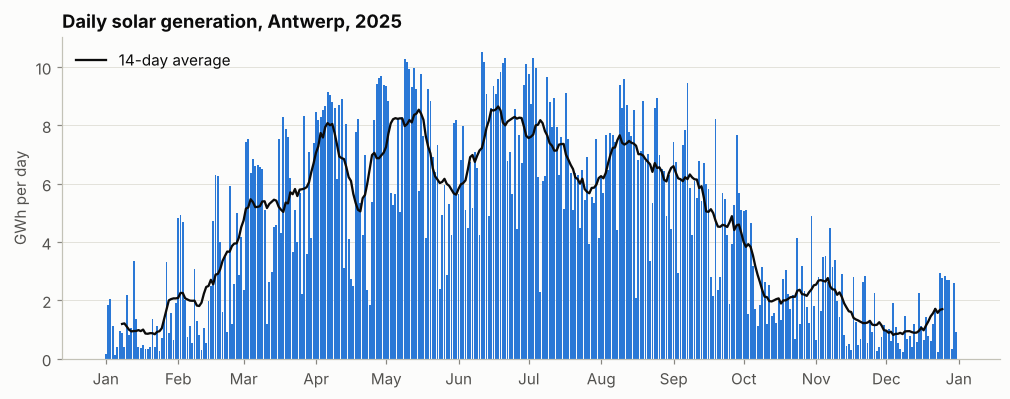

In [11]:
def save(fig, out, name):
    """Show the figure in the notebook, and write it to disk if SAVE_FIGURES is on."""
    if SAVE_FIGURES:
        out.mkdir(exist_ok=True)
        fig.savefig(out / name, dpi=160, bbox_inches="tight")
    plt.show()


OUT = Path("figures")


def fig_daily(df, out):
    be = df[df["region"] == PROVINCE].set_index("datetime")
    daily = be["measured"].resample("D").sum() / 4 / 1000        # MW per 15 min -> GWh
    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.bar(daily.index, daily.values, width=0.8, color=BLUE, linewidth=0)
    ax.plot(daily.index, daily.rolling(14, center=True).mean(), color=INK, linewidth=1.5,
            label="14-day average")
    ax.legend(loc="upper left")
    ax.set_title(f"Daily solar generation, {PROVINCE}, {FIG_YEAR}")
    ax.set_ylabel("GWh per day")
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.grid(axis="x", visible=False)
    save(fig, out, "1_daily_generation.png")


fig_daily(fig_df, OUT)

### 3.2 Load factor by day and time of day
Each column is a day and each row a time of day. Dark is high output. Pale vertical stripes are cloudy days.

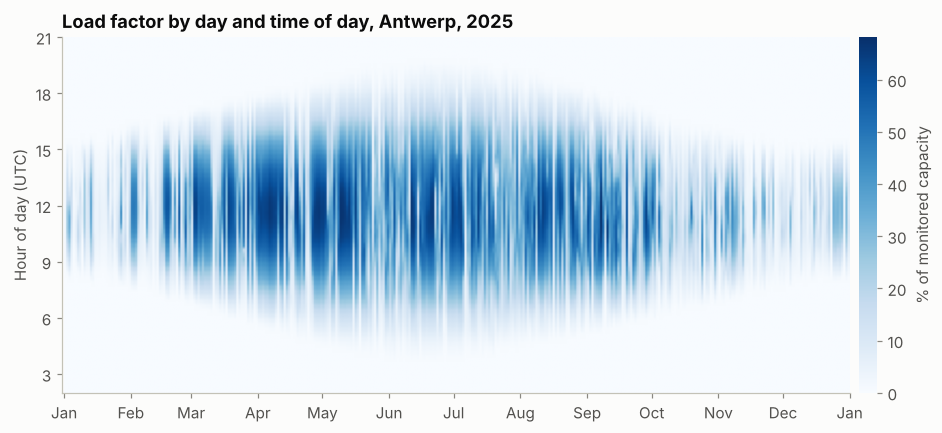

In [12]:
def fig_heatmap(df, out):
    be = df[df["region"] == PROVINCE].copy()
    be["date"] = be["datetime"].dt.tz_convert("UTC").dt.date
    be["tod"] = be["datetime"].dt.tz_convert("UTC").dt.hour + be["datetime"].dt.tz_convert("UTC").dt.minute / 60
    grid = be.pivot_table(index="tod", columns="date", values="lf")
    fig, ax = plt.subplots(figsize=(11, 4.2))
    dates = mdates.date2num(pd.to_datetime(grid.columns))
    im = ax.imshow(grid.values * 100, aspect="auto", origin="lower", cmap="Blues",
                   extent=[dates[0], dates[-1] + 1, 0, 24], vmin=0)
    ax.set_ylim(2, 21)
    ax.set_yticks(range(3, 22, 3))
    ax.set_title(f"Load factor by day and time of day, {PROVINCE}, {FIG_YEAR}")
    ax.set_ylabel("Hour of day (UTC)")
    ax.xaxis_date()
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.grid(False)
    cb = fig.colorbar(im, ax=ax, pad=0.01)
    cb.set_label("% of monitored capacity")
    cb.outline.set_visible(False)
    save(fig, out, "2_load_factor_heatmap.png")


fig_heatmap(fig_df, OUT)

### 3.3 Sample weeks against Elia's day-ahead forecast
A settled week, a changeable week and a winter week, picked automatically from the chosen year.

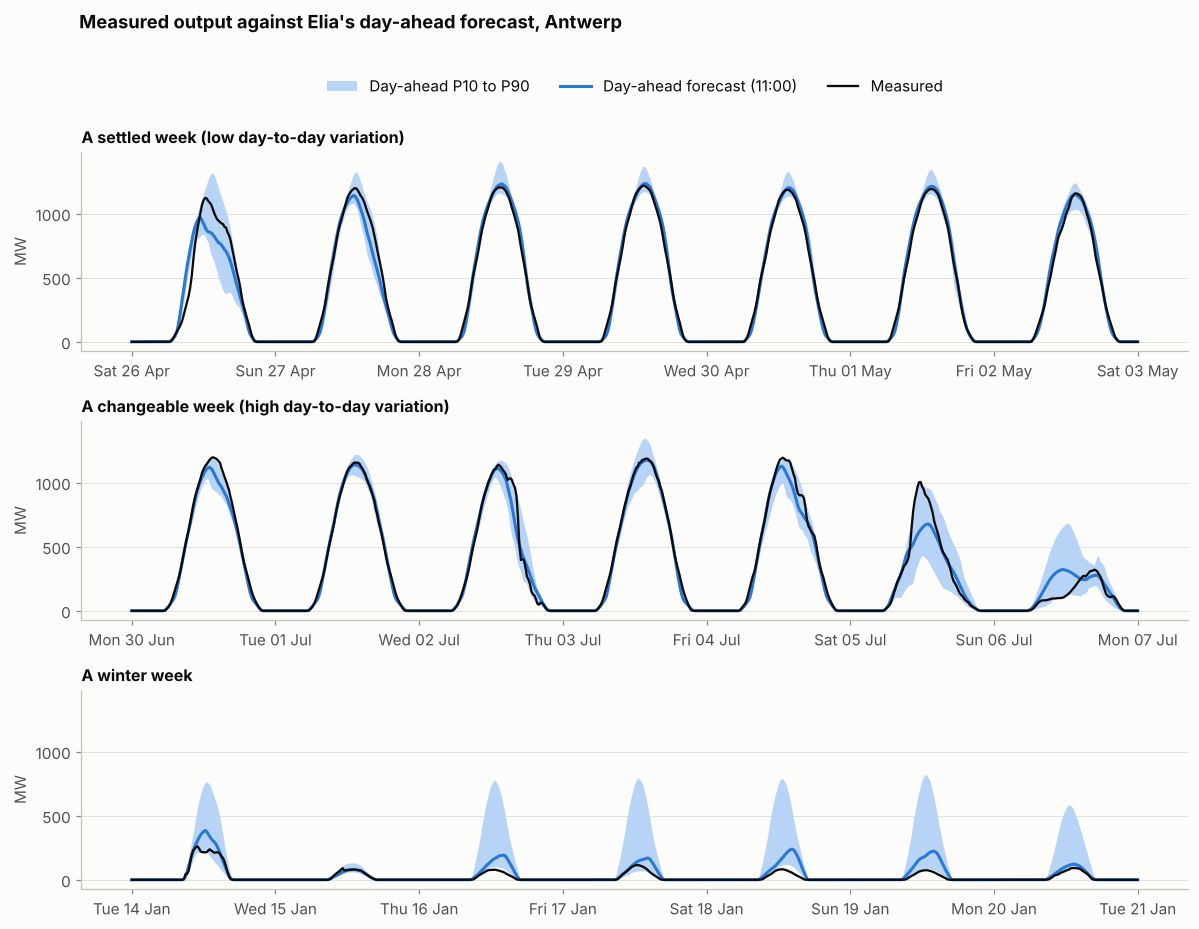

In [13]:
def fig_weeks(df, out):
    be = df[df["region"] == PROVINCE].set_index("datetime")
    daily = be["lf"].resample("D").mean()
    weekly_std = daily.rolling(7).std()
    weekly_mean = daily.rolling(7).mean()
    summer = (daily.index.month >= 5) & (daily.index.month <= 8)
    picks = {
        "A settled week (low day-to-day variation)": weekly_std[summer].idxmin(),
        "A changeable week (high day-to-day variation)": weekly_std[summer].idxmax(),
        "A winter week": weekly_mean[daily.index.month <= 2].dropna().idxmin(),
    }
    fig, axes = plt.subplots(len(picks), 1, figsize=(11, 8.4), sharey=True)
    for ax, (title, end) in zip(axes, picks.items()):
        w = be.loc[end - pd.Timedelta(days=6): end + pd.Timedelta(days=1)]
        ax.fill_between(w.index, w["dayahead11hconfidence10"], w["dayahead11hconfidence90"],
                        color=BLUE_LIGHT, linewidth=0, label="Day-ahead P10 to P90")
        ax.plot(w.index, w["dayahead11hforecast"], color=BLUE, label="Day-ahead forecast (11:00)")
        ax.plot(w.index, w["measured"], color=INK, linewidth=1.5, label="Measured")
        ax.set_title(title, fontsize=10.5)
        ax.set_ylabel("MW")
        ax.xaxis.set_major_locator(mdates.DayLocator(tz=w.index.tz))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b", tz=w.index.tz))
        ax.grid(axis="x", visible=False)
    axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, 1.45), ncol=3)
    fig.suptitle(f"Measured output against Elia's day-ahead forecast, {PROVINCE}",
                 x=0.07, ha="left", fontweight="bold", fontsize=12, y=1.0)
    fig.tight_layout()
    save(fig, out, "3_sample_weeks.png")


fig_weeks(fig_df, OUT)

## 4. Elia's forecasts: the benchmark

### 4.1 Error by lead time, and against the other areas

The left panel is the chosen area. The right panel uses the whole file to show where it sits among the others.

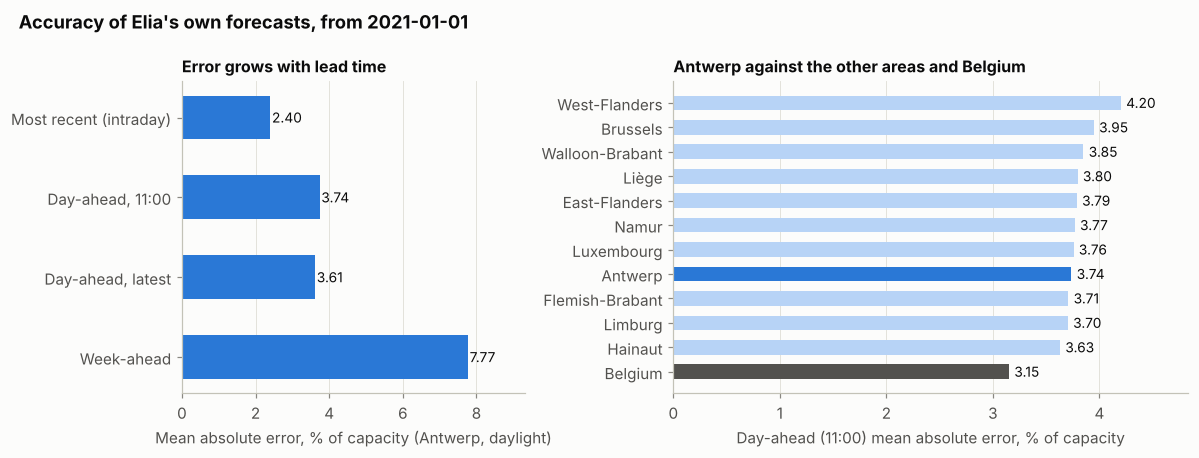

In [14]:
def fig_forecast_error(df, out):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.5]})
    scores = forecast_scores(df, PROVINCE)["nMAE %"].iloc[::-1]
    ax1.barh(scores.index, scores.values, color=BLUE, height=0.55)
    for y, v in enumerate(scores.values):
        ax1.text(v + 0.05, y, f"{v:.2f}", va="center", color=INK, fontsize=9)
    ax1.set_title("Error grows with lead time", fontsize=10.5)
    ax1.set_xlabel(f"Mean absolute error, % of capacity ({PROVINCE}, daylight)")
    ax1.grid(axis="y", visible=False)
    ax1.set_xlim(0, scores.max() * 1.2)

    regions = [r for r in sorted(df["region"].unique()) if r not in AGGREGATES]
    by_region = pd.Series({r: forecast_scores(df, r).loc["Day-ahead, 11:00", "nMAE %"]
                           for r in regions + ["Belgium"]}).sort_values()
    colors = [BLUE if r == PROVINCE else (INK2 if r == "Belgium" else BLUE_LIGHT) for r in by_region.index]
    ax2.barh(by_region.index, by_region.values, color=colors, height=0.6)
    for y, v in enumerate(by_region.values):
        ax2.text(v + 0.05, y, f"{v:.2f}", va="center", color=INK, fontsize=9)
    ax2.set_title(f"{PROVINCE} against the other areas and Belgium", fontsize=10.5)
    ax2.set_xlabel("Day-ahead (11:00) mean absolute error, % of capacity")
    ax2.grid(axis="y", visible=False)
    ax2.set_xlim(0, by_region.max() * 1.15)
    fig.suptitle(f"Accuracy of Elia's own forecasts, from {START}", x=0.02, ha="left",
                 fontweight="bold", fontsize=12)
    fig.tight_layout()
    save(fig, out, "4_forecast_error.png")


fig_forecast_error(areas.dropna(subset=['measured']), OUT)

### 4.2 Calibration of the P10 to P90 bands

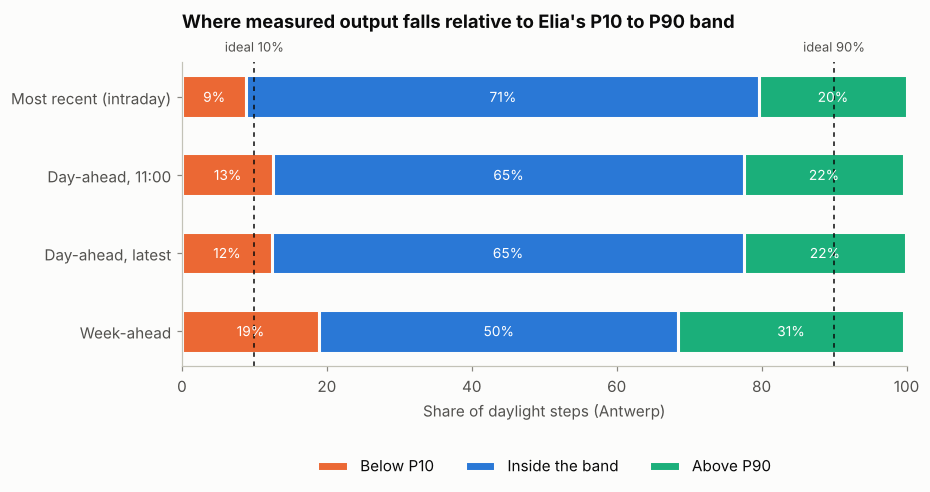

In [15]:
def fig_calibration(df, out):
    s = forecast_scores(df, PROVINCE)[["below P10 %", "inside %", "above P90 %"]]
    fig, ax = plt.subplots(figsize=(8.5, 3.6))
    y = np.arange(len(s))[::-1]
    left = np.zeros(len(s))
    for col, color, label in zip(s.columns, [ORANGE, BLUE, AQUA],
                                 ["Below P10", "Inside the band", "Above P90"]):
        ax.barh(y, s[col], left=left, color=color, height=0.55, edgecolor=SURFACE,
                linewidth=2, label=label)
        for yi, (l, v) in zip(y, zip(left, s[col])):
            if v > 4:
                ax.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
        left += s[col].values
    for x in (10, 90):
        ax.axvline(x, color=INK, linewidth=1, linestyle=(0, (3, 3)))
    ax.text(10, len(s) - 0.42, "ideal 10%", ha="center", fontsize=8.5, color=INK2)
    ax.text(90, len(s) - 0.42, "ideal 90%", ha="center", fontsize=8.5, color=INK2)
    ax.set_yticks(y, s.index)
    ax.set_xlim(0, 100)
    ax.set_xlabel(f"Share of daylight steps ({PROVINCE})")
    ax.set_title("Where measured output falls relative to Elia's P10 to P90 band", pad=22)
    ax.grid(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3)
    save(fig, out, "5_quantile_calibration.png")


fig_calibration(df, OUT)

### 4.3 Forecast against outcome

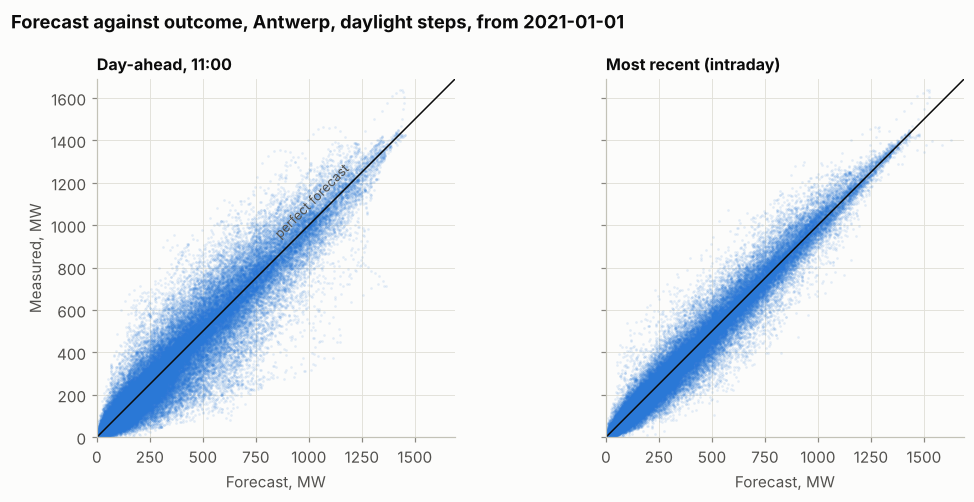

In [16]:
def fig_scatter(df, out):
    be = df[(df["region"] == PROVINCE) & (df["measured"] > 0)]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
    top = max(be["measured"].max(), be["dayahead11hforecast"].max()) * 1.03
    for ax, pre in zip(axes, ["dayahead11h", "mostrecent"]):
        ax.scatter(be[f"{pre}forecast"], be["measured"], s=3, color=BLUE, alpha=0.12, linewidths=0)
        ax.plot([0, top], [0, top], color=INK, linewidth=1)
        ax.set_title(FORECASTS[pre], fontsize=10.5)
        ax.set_xlabel("Forecast, MW")
        ax.set_xlim(0, top), ax.set_ylim(0, top)
        ax.set_aspect("equal")
    axes[0].set_ylabel("Measured, MW")
    axes[0].text(top * 0.60, top * 0.66, "perfect forecast", rotation=45, color=INK2,
                 fontsize=8.5, ha="center", va="center")
    fig.suptitle(f"Forecast against outcome, {PROVINCE}, daylight steps, from {START}", x=0.06, ha="left",
                 fontweight="bold", fontsize=12)
    fig.tight_layout()
    save(fig, out, "6_forecast_vs_measured.png")


fig_scatter(df, OUT)

## What to take from this

Fill this in from the outputs above:

- **Completeness:** missing steps and missing values (2.1, 2.2).
- **Capacity:** how many updates, and how large (2.5).
- **Benchmark:** Elia's day-ahead error, which the project's model is measured against (2.7, 4.1).
- **Weak spots in the benchmark:** bias and band calibration (2.7, 4.2).